In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight


In [ ]:
df=pd.read_csv("/content/adult.csv")

In [ ]:
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K


In [ ]:
# Remove unwanted spaces from column names
df.columns = df.columns.str.strip()

# Remove leading and trailing spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Convert question marks into actual missing values
df.replace("?", np.nan, inplace=True)

# Count missing values before cleaning
print("Missing values before cleaning:")
display(df.isnull().sum().sort_values(ascending=False))

print("Total missing values:", df.isnull().sum().sum())
print("Rows before cleaning:", len(df))

# Remove rows containing missing values
df.dropna(inplace=True)

# Reset the row index
df.reset_index(drop=True, inplace=True)

print("\nRows after cleaning:", len(df))
print("Missing values after cleaning:", df.isnull().sum().sum())

Missing values before cleaning:


,0
occupation,2809
workclass,2799
native-country,857
fnlwgt,0
education,0
educational-num,0
age,0
marital-status,0
relationship,0
gender,0


Total missing values: 6465
Rows before cleaning: 48842

Rows after cleaning: 45222
Missing values after cleaning: 0


In [ ]:
# Check the columns before dropping them
print("Columns before dropping:")
print(df.columns.tolist())

# Drop the redundant columns
columns_to_drop = ["fnlwgt", "education"]

df.drop(
    columns=columns_to_drop,
    errors="ignore",
    inplace=True
)

print("\nColumns after dropping:")
print(df.columns.tolist())

print("\nDataset shape after dropping columns:", df.shape)

Columns before dropping:
['age', 'workclass', 'fnlwgt', 'education', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Columns after dropping:
['age', 'workclass', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Dataset shape after dropping columns: (45222, 13)


In [ ]:
# Inspect the original target values
print(df["income"].value_counts())

# Encode the target
df["income"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

# Check for unexpected labels
print("\nMissing target values after encoding:",
      df["income"].isnull().sum())

# Remove any rows with unrecognized target labels
df.dropna(subset=["income"], inplace=True)

# Convert target to integer
df["income"] = df["income"].astype(int)

print("\nEncoded target distribution:")
display(df["income"].value_counts())

print("\nTarget distribution in percentages:")
display((df["income"].value_counts(normalize=True) * 100).round(2))

income
<=50K    34014
>50K     11208
Name: count, dtype: int64

Missing target values after encoding: 0

Encoded target distribution:


,count
income,
0,34014
1,11208



Target distribution in percentages:


,proportion
income,
0,75.22
1,24.78


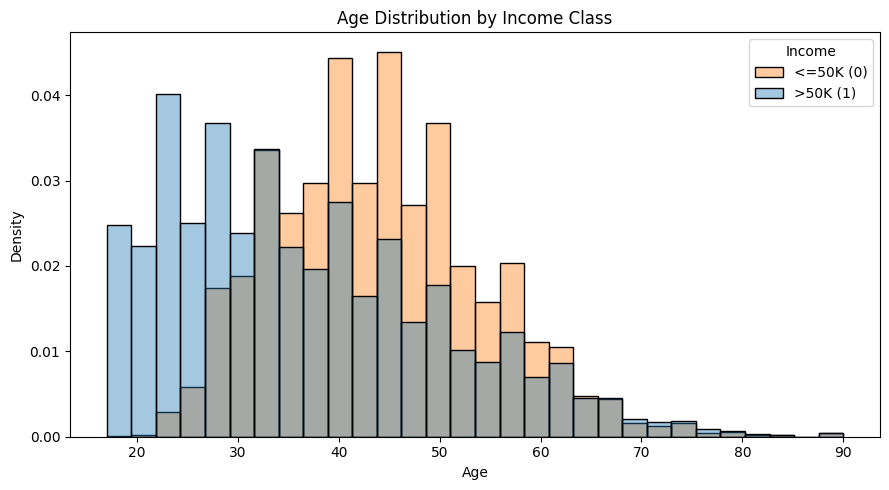

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age",
    hue="income",
    bins=30,
    multiple="layer",
    stat="density",
    common_norm=False,
    alpha=0.4
)

plt.title("Age Distribution by Income Class")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend(title="Income", labels=["<=50K (0)", ">50K (1)"])
plt.tight_layout()
plt.show()

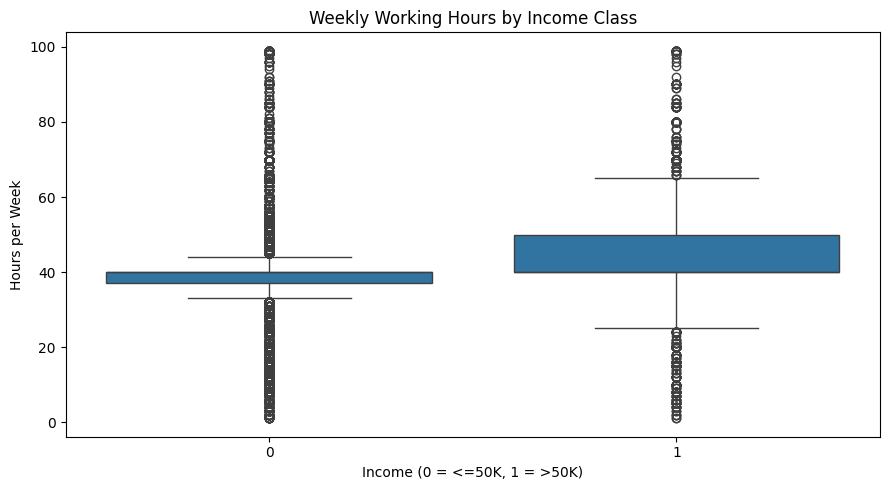

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="income",
    y="hours-per-week"
)

plt.title("Weekly Working Hours by Income Class")
plt.xlabel("Income (0 = <=50K, 1 = >50K)")
plt.ylabel("Hours per Week")
plt.tight_layout()
plt.show()

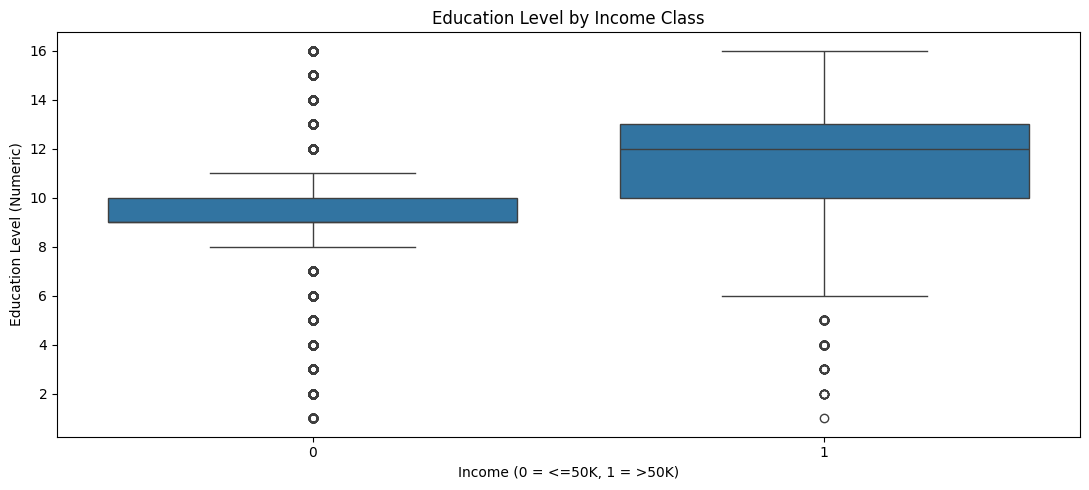

In [ ]:
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df,
    x="income",
    y="educational-num"
)

plt.title("Education Level by Income Class")
plt.xlabel("Income (0 = <=50K, 1 = >50K)")
plt.ylabel("Education Level (Numeric)")
plt.tight_layout()
plt.show()

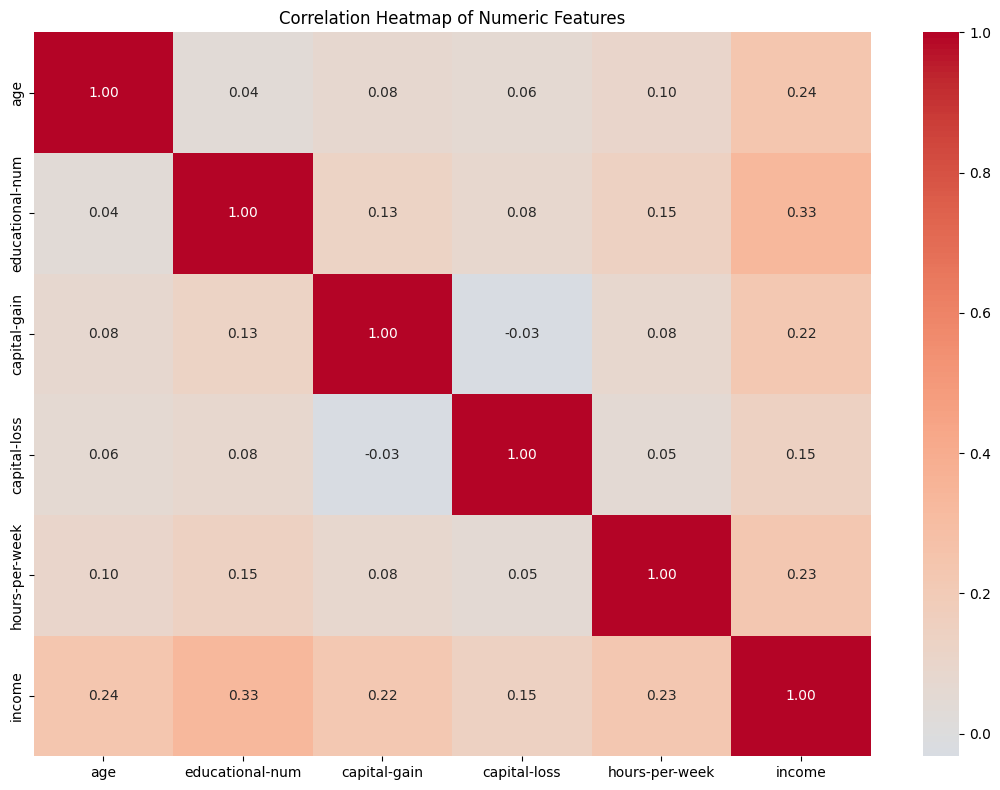

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(11, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

In [ ]:
# Separate features and target
X = df.drop(columns=["income"])
y = df["income"]

# Identify categorical and numeric features
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)

# One-hot encode categorical columns
X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("\nEncoded feature shape:", X_encoded.shape)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale numeric columns only
scaler = StandardScaler()

X_train.loc[:, numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

X_test.loc[:, numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

# Convert features to float32 for TensorFlow
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

# Verify the final data
print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).round(3))

print("\nTask 1 preprocessing completed!")

Categorical columns: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country']
Numeric columns: ['age', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Encoded feature shape: (45222, 80)

Training features: (36177, 80)
Testing features: (9045, 80)
Training target: (36177,)
Testing target: (9045,)

Training class proportions:


/tmp/ipykernel_1169/4159963454.py:39: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.26789621 -1.47640119 -0.8721487  ...  0.26082472 -1.17427495
 -1.47640119]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_cols] = scaler.fit_transform(
/tmp/ipykernel_1169/4159963454.py:39: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.43615486 -0.43615486 -0.43615486 ...  1.90323196  1.12343636
 -0.43615486]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_cols] = scaler.fit_transform(
/tmp/ipykernel_1169/4159963454.py:39: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.14779435 -0.14779435 -0.14779435 ... -0.14779435 -0.14779435
 -0.14779435]' has dtyp

,proportion
income,
0,0.752
1,0.248



Testing class proportions:


,proportion
income,
0,0.752
1,0.248



Task 1 preprocessing completed!


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def build_ann(
    input_dim,
    hidden_units=(128, 64),
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
):
    model = keras.Sequential()

    # Input layer and first hidden layer
    model.add(
        layers.Dense(
            hidden_units[0],
            input_shape=(input_dim,),
            activation=None,
            kernel_initializer=initializer
        )
    )

    if use_batch_norm:
        model.add(layers.BatchNormalization())

    model.add(layers.Activation(activation))

    # Second hidden layer
    model.add(
        layers.Dense(
            hidden_units[1],
            activation=None,
            kernel_initializer=initializer
        )
    )

    if use_batch_norm:
        model.add(layers.BatchNormalization())

    model.add(layers.Activation(activation))

    # Output layer for binary classification
    model.add(
        layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=["accuracy"]
    )

    return model

print("Reusable ANN function created successfully!")


Reusable ANN function created successfully!


In [ ]:

input_dim = X_train.shape[1]

model_base = build_ann(
    input_dim=input_dim,
    hidden_units=(128, 64),
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)

model_base.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

history_base = model_base.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("Baseline ANN training completed!")


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8435 - loss: 0.3328 - val_accuracy: 0.8483 - val_loss: 0.3265
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8533 - loss: 0.3145 - val_accuracy: 0.8538 - val_loss: 0.3232
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8548 - loss: 0.3119 - val_accuracy: 0.8502 - val_loss: 0.3253
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8546 - loss: 0.3082 - val_accuracy: 0.8496 - val_loss: 0.3246
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8564 - loss: 0.3064 - val_accuracy: 0.8505 - val_loss: 0.3218
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8576 - loss: 0.3028 - val_accuracy: 0.8494 - val_loss: 0.3211
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8603 - loss: 0.3008 - val_accuracy: 0.8521 - val_loss: 0.3223
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8612 - loss: 0.2982 - val_accuracy: 0.

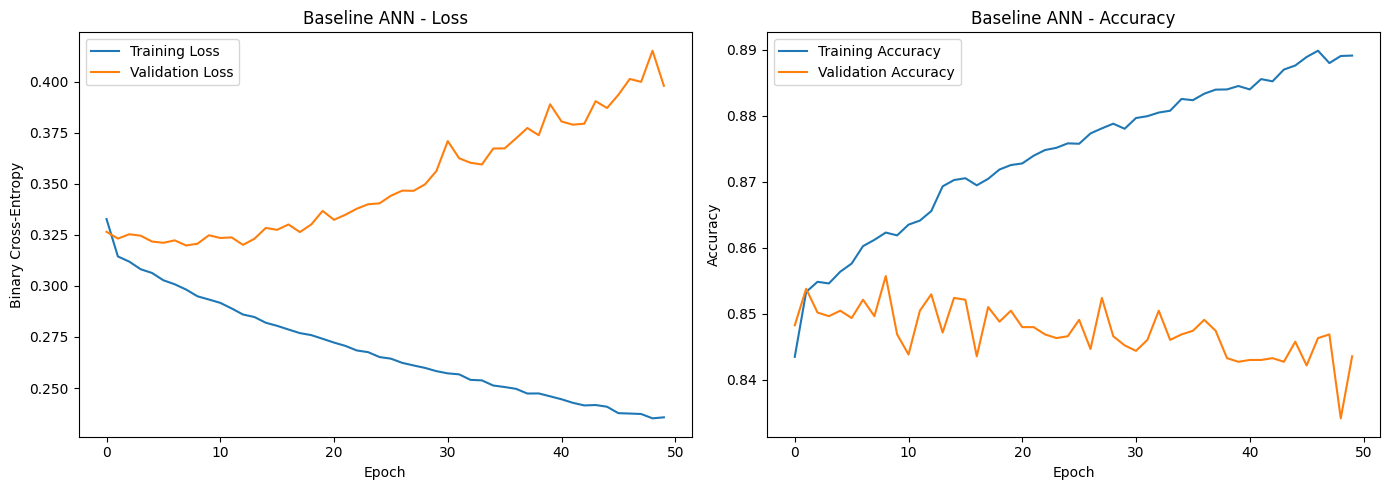

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(history_base.history["loss"], label="Training Loss")
axes[0].plot(history_base.history["val_loss"], label="Validation Loss")
axes[0].set_title("Baseline ANN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].legend()

# Accuracy curves
axes[1].plot(history_base.history["accuracy"], label="Training Accuracy")
axes[1].plot(history_base.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Baseline ANN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

Accuracy: 0.8402
Precision for >50K: 0.6974
Recall for >50K: 0.628
F1-score for >50K: 0.6609

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.90      6803
        >50K       0.70      0.63      0.66      2242

    accuracy                           0.84      9045
   macro avg       0.79      0.77      0.78      9045
weighted avg       0.84      0.84      0.84      9045



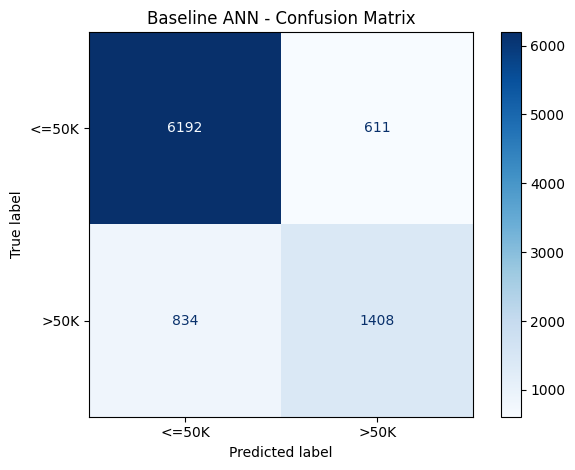

In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# Predict probabilities
y_pred_prob = model_base.predict(X_test, verbose=0).ravel()

# Convert probabilities to binary labels
y_pred = (y_pred_prob >= 0.5).astype(int)

# Print metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision for >50K:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall for >50K:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score for >50K:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["<=50K", ">50K"],
        zero_division=0
    )
)

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<=50K", ">50K"]
).plot(cmap="Blues", values_format="d")

plt.title("Baseline ANN - Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Task 3.1: Train models with different activation functions

activation_functions = ["relu", "tanh", "sigmoid", "elu"]
activation_histories = {}
activation_models = {}

for activation in activation_functions:
    print(f"\nTraining model with {activation.upper()} activation...")

    model = build_ann(
        input_dim=X_train.shape[1],
        hidden_units=(128, 64),
        activation=activation,
        initializer="glorot_uniform",
        use_batch_norm=False,
        optimizer="adam",
        loss="binary_crossentropy"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    activation_models[activation] = model
    activation_histories[activation] = history

    print(
        f"Final training accuracy: "
        f"{history.history['accuracy'][-1]:.4f}"
    )
    print(
        f"Final validation accuracy: "
        f"{history.history['val_accuracy'][-1]:.4f}"
    )

print("\nAll four activation experiments completed!")



Training model with RELU activation...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final training accuracy: 0.8909
Final validation accuracy: 0.8430

Training model with TANH activation...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final training accuracy: 0.8774
Final validation accuracy: 0.8513

Training model with SIGMOID activation...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final training accuracy: 0.8583
Final validation accuracy: 0.8574

Training model with ELU activation...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final training accuracy: 0.8688
Final validation accuracy: 0.8552

All four activation experiments completed!


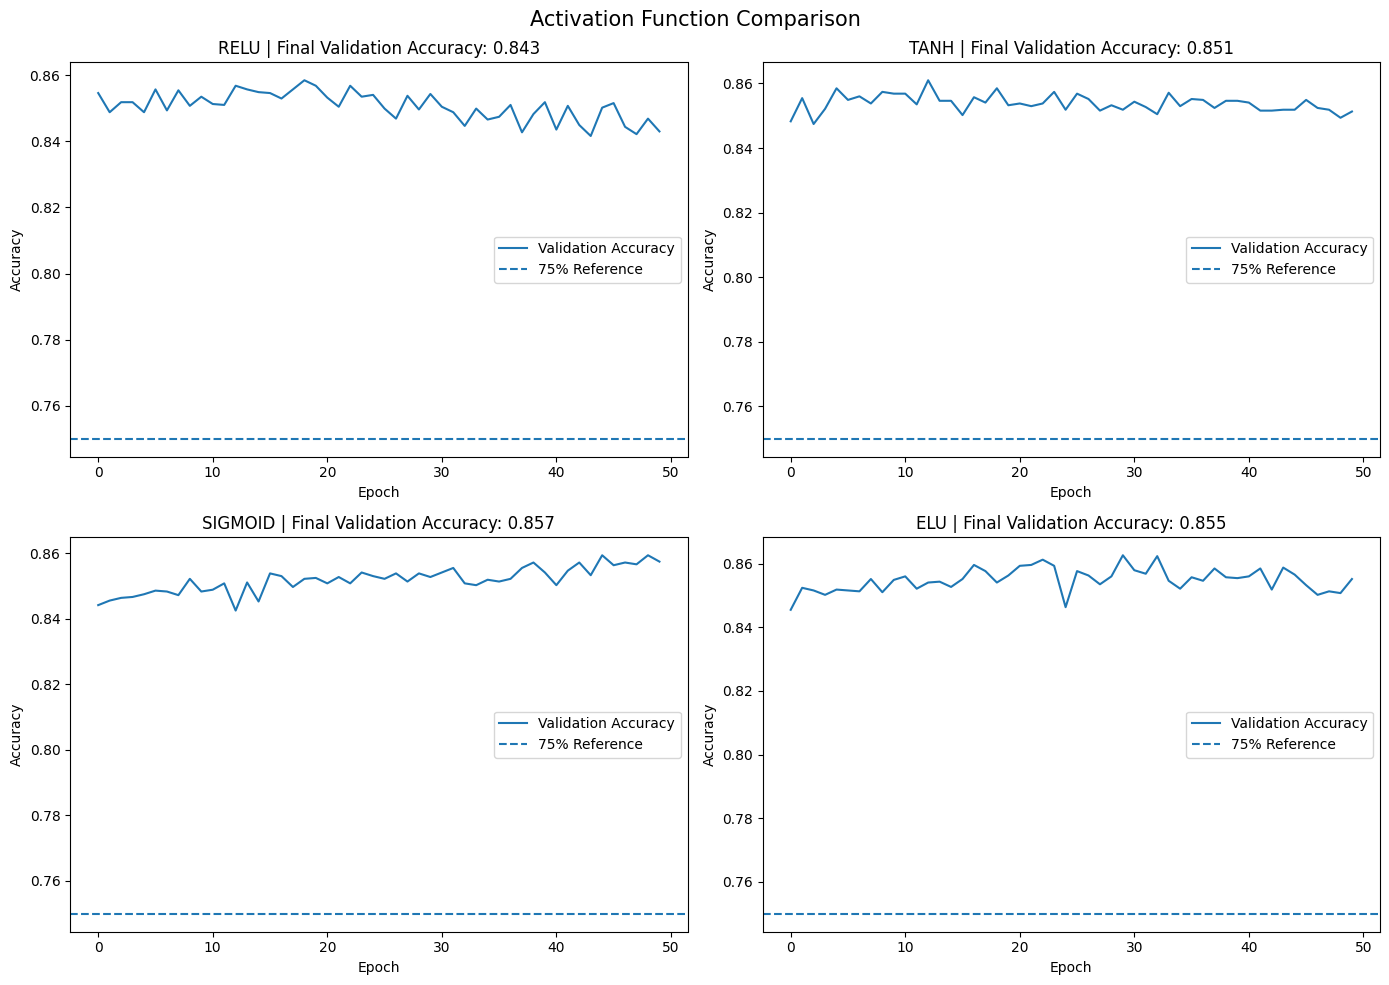

In [ ]:

# Task 3.2: Compare validation accuracy

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, activation in zip(axes, activation_functions):
    history = activation_histories[activation]

    ax.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    ax.axhline(
        y=0.75,
        linestyle="--",
        label="75% Reference"
    )

    final_val_acc = history.history["val_accuracy"][-1]

    ax.set_title(
        f"{activation.upper()} | Final Validation Accuracy: "
        f"{final_val_acc:.3f}"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()

plt.suptitle("Activation Function Comparison", fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:

# Use the same held-out test set for all activation models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

activation_results = []

for activation in activation_functions:
    model = activation_models[activation]

    y_prob = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    history = activation_histories[activation]

    activation_results.append({
        "Activation": activation,
        "Final Train Accuracy": history.history["accuracy"][-1],
        "Final Validation Accuracy": history.history["val_accuracy"][-1],
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Class 1)": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall (Class 1)": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score (Class 1)": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

activation_results_df = pd.DataFrame(activation_results)

display(
    activation_results_df.sort_values(
        by="F1-score (Class 1)",
        ascending=False
    ).round(4)
)


,Activation,Final Train Accuracy,Final Validation Accuracy,Test Accuracy,Precision (Class 1),Recall (Class 1),F1-score (Class 1)
1,tanh,0.8774,0.8513,0.8471,0.6969,0.6780,0.6873
3,elu,0.8688,0.8552,0.8473,0.7099,0.6494,0.6783
2,sigmoid,0.8583,0.8574,0.8534,0.7522,0.6093,0.6732
0,relu,0.8909,0.8430,0.8391,0.7410,0.5397,0.6245


Activation matrix shape: (500, 128)
Fraction of activations equal to zero: 0.6155
Number of completely inactive neurons: 0
Fraction of completely inactive neurons: 0.0


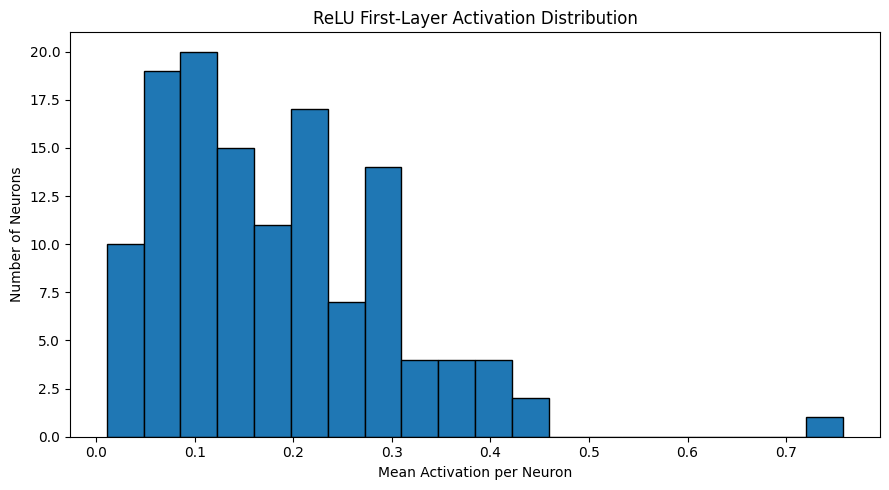

In [ ]:

# Task 3.3: Inspect first hidden-layer ReLU activations

model_relu = activation_models["relu"]

# Extract output of the first ReLU activation layer
first_hidden_layer = keras.Model(
    inputs=model_relu.inputs,
    outputs=model_relu.layers[1].output
)

# Select 500 test samples
sample_count = min(500, len(X_test))
X_sample = X_test.iloc[:sample_count]

# Calculate hidden-layer activations
activations = first_hidden_layer.predict(
    X_sample,
    verbose=0
)

# Fraction of all activations equal to zero
dead_fraction = np.mean(activations == 0)

# Fraction of neurons that are zero for every sample
dead_neurons = np.all(activations == 0, axis=0)
dead_neuron_fraction = np.mean(dead_neurons)

print("Activation matrix shape:", activations.shape)
print("Fraction of activations equal to zero:",
      round(float(dead_fraction), 4))
print("Number of completely inactive neurons:",
      int(dead_neurons.sum()))
print("Fraction of completely inactive neurons:",
      round(float(dead_neuron_fraction), 4))

# Histogram of mean activation per neuron
mean_activation_per_neuron = activations.mean(axis=0)

plt.figure(figsize=(9, 5))
plt.hist(mean_activation_per_neuron, bins=20, edgecolor="black")
plt.title("ReLU First-Layer Activation Distribution")
plt.xlabel("Mean Activation per Neuron")
plt.ylabel("Number of Neurons")
plt.tight_layout()
plt.show()


,Layer,Mean Absolute Weight Gradient
0,dense_9,0.000160
1,dense_10,0.000319
2,dense_11,0.007246


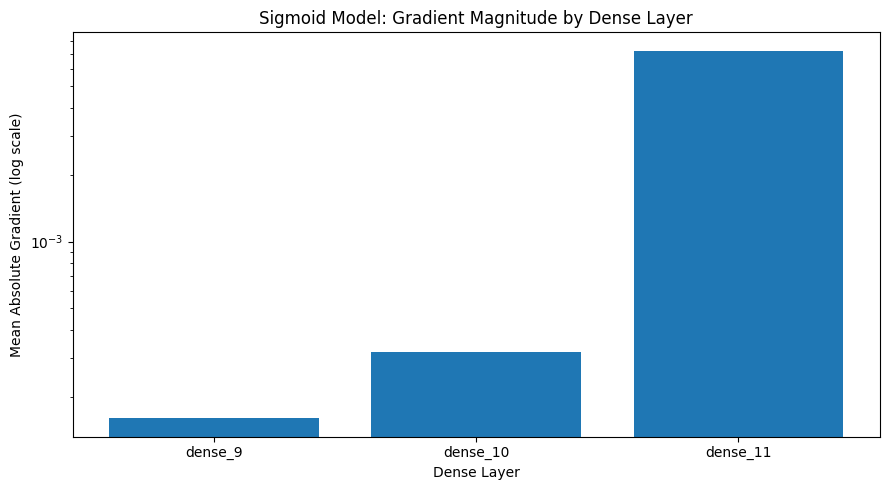

In [ ]:

# Task 3.4: Inspect gradient magnitudes in the sigmoid model

model_sigmoid = activation_models["sigmoid"]

# Use a small batch from the test set
X_gradient = tf.convert_to_tensor(
    X_test.iloc[:256].to_numpy(),
    dtype=tf.float32
)

y_gradient = tf.convert_to_tensor(
    y_test.iloc[:256].to_numpy().reshape(-1, 1),
    dtype=tf.float32
)

with tf.GradientTape() as tape:
    predictions = model_sigmoid(X_gradient, training=False)

    loss_value = keras.losses.binary_crossentropy(
        y_gradient,
        predictions
    )
    loss_value = tf.reduce_mean(loss_value)

gradients = tape.gradient(
    loss_value,
    model_sigmoid.trainable_variables
)

gradient_records = []

for layer in model_sigmoid.layers:
    if isinstance(layer, layers.Dense):
        gradient_records.append(layer.name)

# Pair the trainable weight gradients with the Dense layers
dense_layers = [
    layer for layer in model_sigmoid.layers
    if isinstance(layer, layers.Dense)
]

weight_gradients = gradients[0::2]

layer_gradient_means = []

for layer, grad in zip(dense_layers, weight_gradients):
    mean_gradient = (
        float(tf.reduce_mean(tf.abs(grad)).numpy())
        if grad is not None else 0.0
    )

    layer_gradient_means.append({
        "Layer": layer.name,
        "Mean Absolute Weight Gradient": mean_gradient
    })

gradient_df = pd.DataFrame(layer_gradient_means)
display(gradient_df.round(8))

plt.figure(figsize=(9, 5))
plt.bar(
    gradient_df["Layer"],
    gradient_df["Mean Absolute Weight Gradient"]
)
plt.yscale("log")
plt.title("Sigmoid Model: Gradient Magnitude by Dense Layer")
plt.xlabel("Dense Layer")
plt.ylabel("Mean Absolute Gradient (log scale)")
plt.tight_layout()
plt.show()


In [ ]:

def build_ann(
    input_dim,
    hidden_units=(128, 64),
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
):
    model = keras.Sequential()

    for i, units in enumerate(hidden_units):
        if i == 0:
            model.add(
                layers.Dense(
                    units,
                    input_shape=(input_dim,),
                    kernel_initializer=initializer
                )
            )
        else:
            model.add(
                layers.Dense(
                    units,
                    kernel_initializer=initializer
                )
            )

        if use_batch_norm:
            model.add(layers.BatchNormalization())

        model.add(layers.Activation(activation))

    model.add(
        layers.Dense(
            1,
            activation="sigmoid",
            kernel_initializer=initializer
        )
    )

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=["accuracy"]
    )

    return model

print("Updated ANN builder successfully!")


Updated ANN builder successfully!


In [ ]:

# Task 4.1: Weight initialization comparison

initializers = [
    "glorot_uniform",
    "glorot_normal",
    "he_uniform",
    "he_normal",
    "zeros"
]

initializer_models = {}
initializer_histories = {}

for init_name in initializers:
    print(f"\nTraining with initializer: {init_name}")

    model = build_ann(
        input_dim=X_train.shape[1],
        hidden_units=(128, 64),
        activation="relu",
        initializer=init_name,
        use_batch_norm=False,
        optimizer="adam",
        loss="binary_crossentropy"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    initializer_models[init_name] = model
    initializer_histories[init_name] = history

    print(
        "Final validation accuracy:",
        round(history.history["val_accuracy"][-1], 4)
    )

print("\nAll initialization experiments completed!")



Training with initializer: glorot_uniform


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final validation accuracy: 0.8408

Training with initializer: glorot_normal


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final validation accuracy: 0.8455

Training with initializer: he_uniform


...

Final validation accuracy: 0.8436

Training with initializer: he_normal


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final validation accuracy: 0.8455

Training with initializer: zeros


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final validation accuracy: 0.7526

All initialization experiments completed!


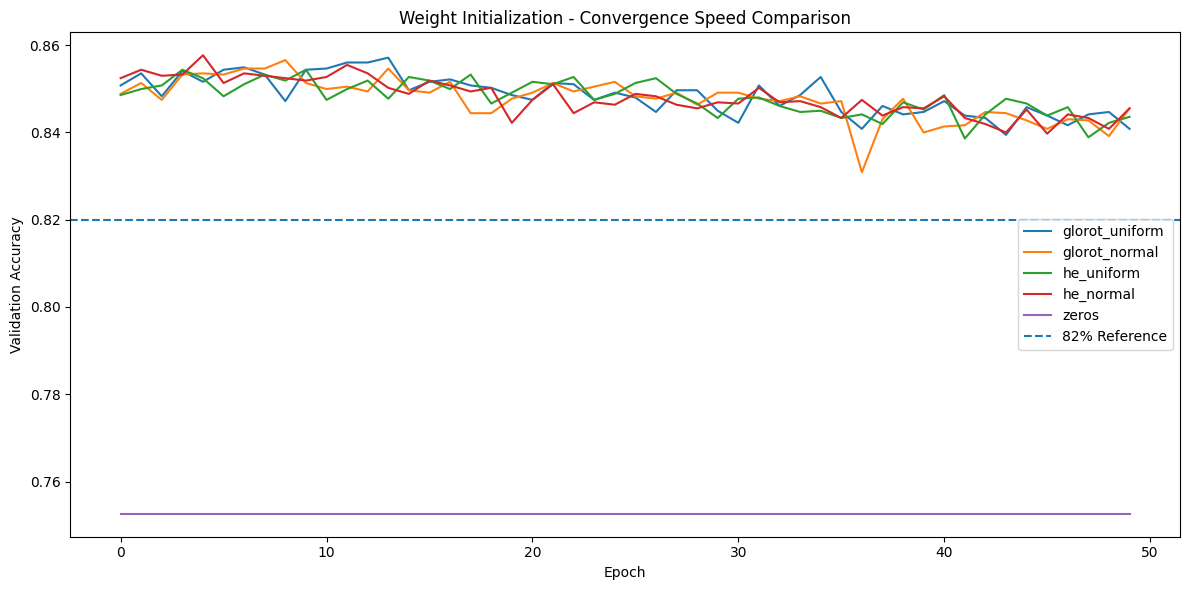

In [ ]:

# Task 4.3: Plot validation accuracy for all initializers

plt.figure(figsize=(12, 6))

for init_name in initializers:
    history = initializer_histories[init_name]

    plt.plot(
        history.history["val_accuracy"],
        label=init_name
    )

plt.axhline(
    y=0.82,
    linestyle="--",
    label="82% Reference"
)

plt.title("Weight Initialization - Convergence Speed Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


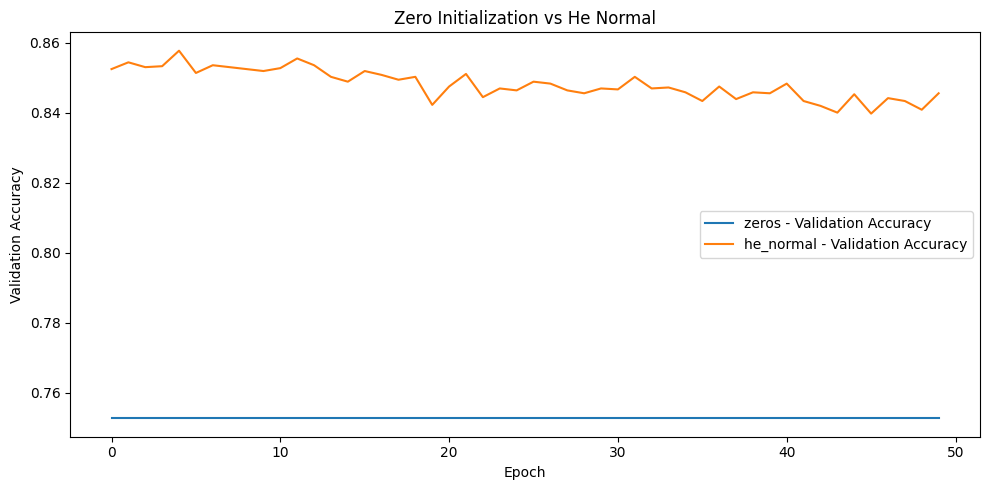


Initializer: zeros
Final training accuracy: 0.7521
Final validation accuracy: 0.7526

Initializer: he_normal
Final training accuracy: 0.8902
Final validation accuracy: 0.8455


In [ ]:

# Task 4.4: Compare zero initialization with a standard initializer

plt.figure(figsize=(10, 5))

for init_name in ["zeros", "he_normal"]:
    history = initializer_histories[init_name]

    plt.plot(
        history.history["val_accuracy"],
        label=f"{init_name} - Validation Accuracy"
    )

plt.title("Zero Initialization vs He Normal")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Inspect final training and validation performance
for init_name in ["zeros", "he_normal"]:
    history = initializer_histories[init_name]

    print(f"\nInitializer: {init_name}")
    print("Final training accuracy:",
          round(history.history["accuracy"][-1], 4))
    print("Final validation accuracy:",
          round(history.history["val_accuracy"][-1], 4))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


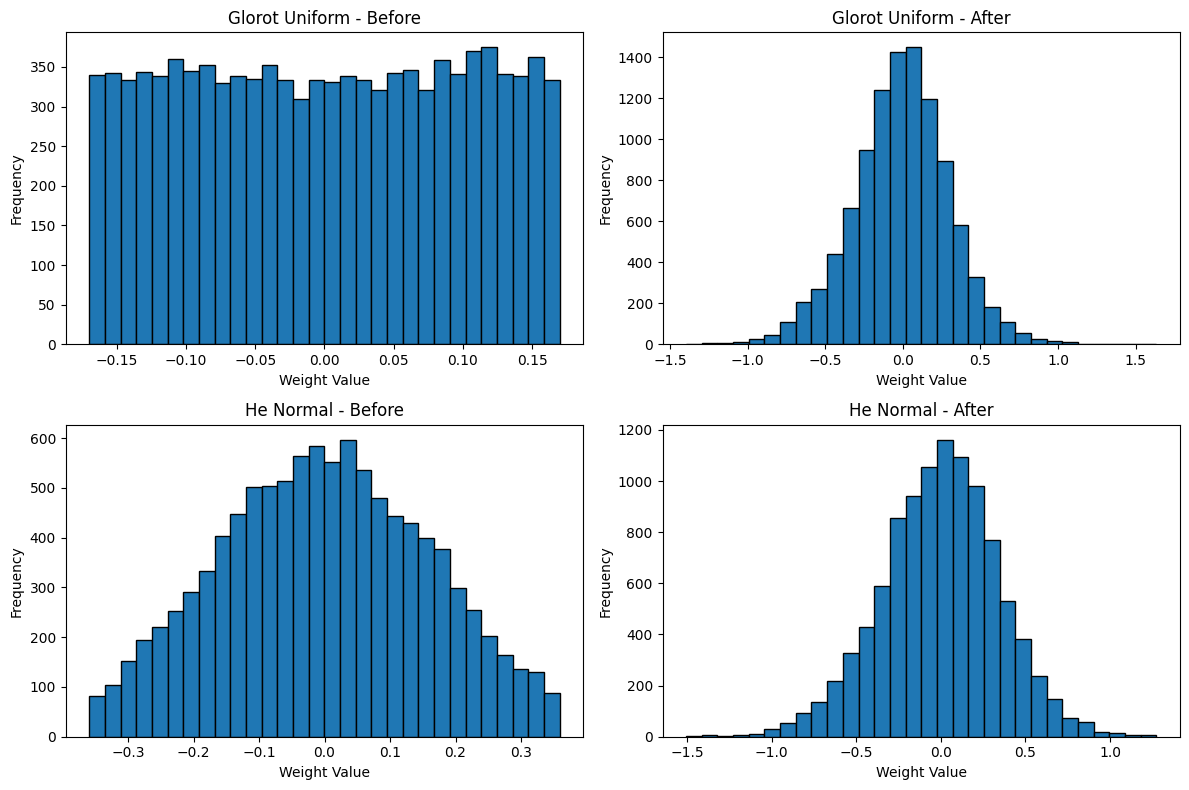

In [ ]:

# Task 4.5: Compare initial and trained weight distributions

def get_first_dense_weights(model):
    for layer in model.layers:
        if isinstance(layer, layers.Dense):
            return layer.get_weights()[0].flatten()
    raise ValueError("No Dense layer found.")

# Create fresh, untrained models
glorot_before_model = build_ann(
    input_dim=X_train.shape[1],
    activation="relu",
    initializer="glorot_uniform"
)

he_before_model = build_ann(
    input_dim=X_train.shape[1],
    activation="relu",
    initializer="he_normal"
)

# Extract weights before training
glorot_before = get_first_dense_weights(glorot_before_model)
he_before = get_first_dense_weights(he_before_model)

# Extract weights after training
glorot_after = get_first_dense_weights(
    initializer_models["glorot_uniform"]
)

he_after = get_first_dense_weights(
    initializer_models["he_normal"]
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_data = [
    (axes[0, 0], glorot_before, "Glorot Uniform - Before"),
    (axes[0, 1], glorot_after, "Glorot Uniform - After"),
    (axes[1, 0], he_before, "He Normal - Before"),
    (axes[1, 1], he_after, "He Normal - After")
]

for ax, weights, title in plot_data:
    ax.hist(weights, bins=30, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Weight Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


In [ ]:

# Task 5.1: Verify baseline loss function

print("Baseline model loss:", model_base.loss)

assert model_base.loss == "binary_crossentropy"

print("Binary cross-entropy is correctly configured.")


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8444 - loss: 0.1076 - val_accuracy: 0.8513 - val_loss: 0.1043
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8537 - loss: 0.1009 - val_accuracy: 0.8494 - val_loss: 0.1044
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8555 - loss: 0.0996 - val_accuracy: 0.8527 - val_loss: 0.1020
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8577 - loss: 0.0983 - val_accuracy: 0.8480 - val_loss: 0.1024
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8586 - loss: 0.0973 - val_accuracy: 0.8549 - val_loss: 0.1013
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8605 - loss: 0.0963 - val_accuracy: 0.8560 - val_loss: 0.1015
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8619 - loss: 0.0954 - val_accuracy: 0.8574 - val_loss: 0.1010
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8634 - loss: 0.0949 - val_accuracy: 0.

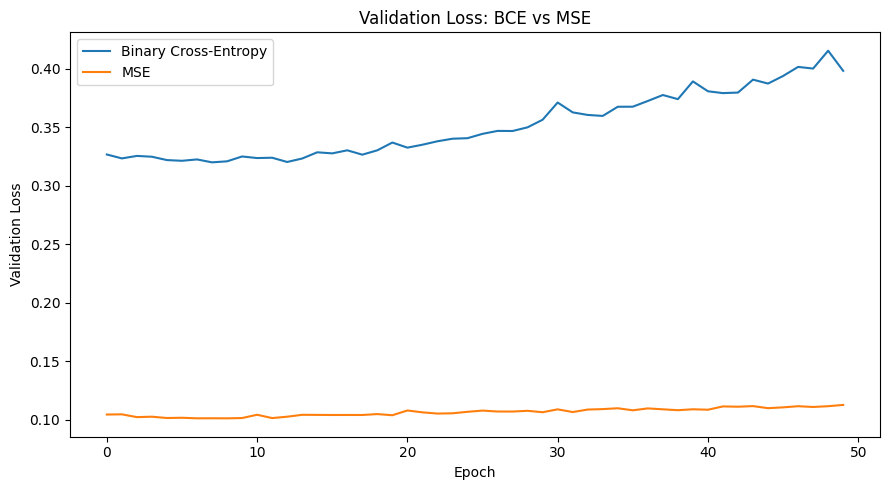

In [ ]:

# Task 5.2: MSE versus Binary Cross-Entropy

model_mse = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer="adam",
    loss="mean_squared_error"
)

history_mse = model_mse.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

# Plot validation loss
plt.figure(figsize=(9, 5))

plt.plot(
    history_base.history["val_loss"],
    label="Binary Cross-Entropy"
)
plt.plot(
    history_mse.history["val_loss"],
    label="MSE"
)

plt.title("Validation Loss: BCE vs MSE")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.asarray(y_train)
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Class weights:", class_weights)


Class weights: {0: 0.6647495498144133, 1: 2.0174548293553425}


In [ ]:

# Task 5.3: Weighted Binary Cross-Entropy

model_wbce = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)

history_wbce = model_wbce.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    class_weight=class_weights,
    verbose=1
)

print("Weighted BCE training completed.")


Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


509/509 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7998 - loss: 0.3953 - val_accuracy: 0.8035 - val_loss: 0.3898
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8072 - loss: 0.3729 - val_accuracy: 0.7980 - val_loss: 0.3922
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8126 - loss: 0.3679 - val_accuracy: 0.7946 - val_loss: 0.3993
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8144 - loss: 0.3633 - val_accuracy: 0.8043 - val_loss: 0.3777
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8162 - loss: 0.3594 - val_accuracy: 0.8306 - val_loss: 0.3545
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8195 - loss: 0.3577 - val_accuracy: 0.7828 - val_loss: 0.4294
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8193 - loss: 0.3532 - val_accuracy: 0.8121 - val_loss: 0.3706
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8218 - loss: 0.3503 - val_accuracy: 0.7946 - val_

In [ ]:

# Task 5.4: Define Focal Loss

def focal_loss(alpha=0.25, gamma=2.0):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)

        # Avoid log(0)
        epsilon = keras.backend.epsilon()
        y_pred = tf.clip_by_value(
            y_pred,
            epsilon,
            1.0 - epsilon
        )

        # Probability assigned to the true class
        p_t = (
            y_true * y_pred
            + (1.0 - y_true) * (1.0 - y_pred)
        )

        # Alpha weighting for the two classes
        alpha_t = (
            alpha * y_true
            + (1.0 - alpha) * (1.0 - y_true)
        )

        focal_weight = alpha_t * tf.pow(
            1.0 - p_t,
            gamma
        )

        bce = -(
            y_true * tf.math.log(y_pred)
            + (1.0 - y_true)
            * tf.math.log(1.0 - y_pred)
        )

        return tf.reduce_mean(focal_weight * bce)

    return loss_fn


# Build the focal-loss model
model_focal = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer="adam",
    loss=focal_loss(alpha=0.25, gamma=2.0)
)

history_focal = model_focal.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("Focal Loss training completed.")


Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8190 - loss: 0.0349 - val_accuracy: 0.8226 - val_loss: 0.0333
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8294 - loss: 0.0326 - val_accuracy: 0.8173 - val_loss: 0.0335
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8319 - loss: 0.0321 - val_accuracy: 0.8121 - val_loss: 0.0337
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8335 - loss: 0.0318 - val_accuracy: 0.8273 - val_loss: 0.0330
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8348 - loss: 0.0314 - val_accuracy: 0.8320 - val_loss: 0.0333
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8373 - loss: 0.0311 - val_accuracy: 0.8214 - val_loss: 0.0335
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8374 - loss: 0.0308 - val_accuracy: 0.8347 - val_loss: 0.0331
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8393 - loss: 0.0304 - val_accuracy: 0.8228 - val_

Loss function performance table:


,Model,F1-score (Class 1)
0,Binary Cross-Entropy,0.6609
1,Mean Squared Error,0.6607
2,Weighted BCE,0.6766
3,Focal Loss,0.5447


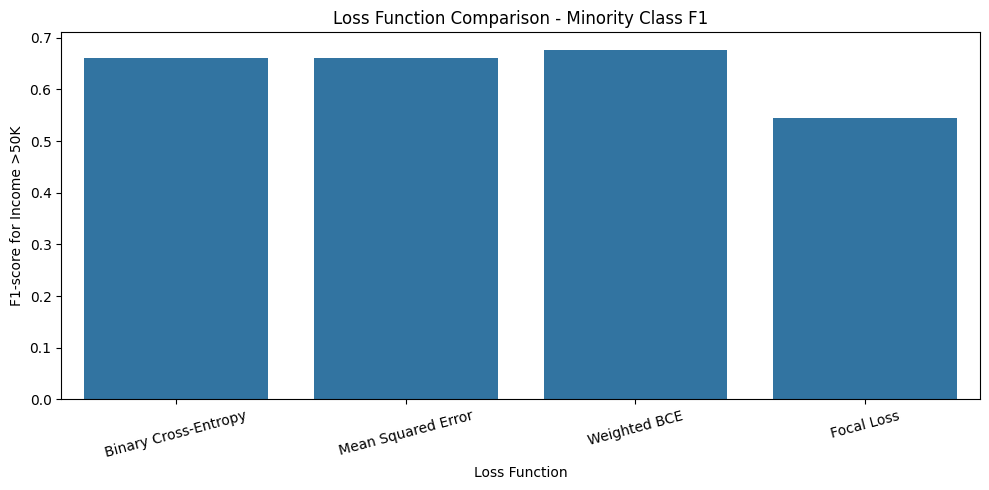

In [ ]:
from sklearn.metrics import f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate and collect F1-scores for all four loss function models
loss_models = {
    "Binary Cross-Entropy": model_base,
    "Mean Squared Error": model_mse,
    "Weighted BCE": model_wbce,
    "Focal Loss": model_focal
}

loss_results = []

for name, model in loss_models.items():
    y_prob = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    loss_results.append({
        "Model": name,
        "F1-score (Class 1)": f1
    })

loss_results_df = pd.DataFrame(loss_results)

print("Loss function performance table:")
display(loss_results_df.round(4))

# Plot the comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=loss_results_df,
    x="Model",
    y="F1-score (Class 1)"
)

plt.title("Loss Function Comparison - Minority Class F1")
plt.xlabel("Loss Function")
plt.ylabel("F1-score for Income >50K")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:

# Task 6.1: Baseline vs Batch Normalization

def build_ann_bn(
    input_dim,
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    bn_position="before"
):
    model = keras.Sequential()
    model.add(keras.Input(shape=(input_dim,)))

    for units in hidden_units:
        model.add(
            layers.Dense(
                units,
                kernel_initializer=initializer,
                use_bias=(bn_position == "after")
            )
        )

        if bn_position == "before":
            model.add(layers.BatchNormalization())
            model.add(layers.Activation(activation))
        else:
            model.add(layers.Activation(activation))
            model.add(layers.BatchNormalization())

    model.add(
        layers.Dense(1, activation="sigmoid")
    )

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Fair baseline: same architecture and initialization, without BatchNorm
model_task6_base = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)

# BatchNorm before activation
model_bn = build_ann_bn(
    input_dim=X_train.shape[1],
    bn_position="before"
)

print("Baseline parameters:", model_task6_base.count_params())
print("BatchNorm parameters:", model_bn.count_params())

model_task6_base.summary()
model_bn.summary()


Baseline parameters: 18689
BatchNorm parameters: 19265


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_45 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_30 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_31 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

...

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_48 (Dense)                │ (None, 128)            │        10,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_32 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_33 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,265 (75.25 KB)

 Trainable params: 18,881 (73.75 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:

# Train the baseline
history_task6_base = model_task6_base.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

# Train the BatchNorm model
history_bn = model_bn.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("Both models trained successfully.")


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8398 - loss: 0.3372 - val_accuracy: 0.8413 - val_loss: 0.3321
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8531 - loss: 0.3150 - val_accuracy: 0.8496 - val_loss: 0.3215
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8543 - loss: 0.3108 - val_accuracy: 0.8535 - val_loss: 0.3197
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8560 - loss: 0.3071 - val_accuracy: 0.8532 - val_loss: 0.3197
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8586 - loss: 0.3047 - val_accuracy: 0.8483 - val_loss: 0.3201
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8578 - loss: 0.3022 - val_accuracy: 0.8527 - val_loss: 0.3216
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8611 - loss: 0.2993 - val_accuracy: 0.8535 - val_loss: 0.3165
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8617 - loss: 0.2973 - val_accuracy: 0.

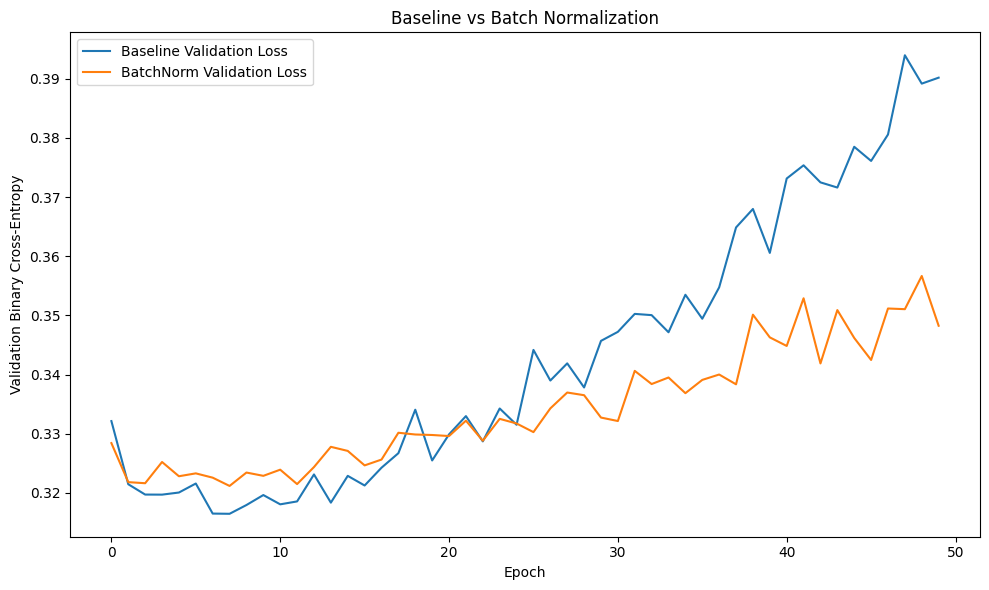

In [ ]:

# Compare loss curves

plt.figure(figsize=(10, 6))

plt.plot(
    history_task6_base.history["val_loss"],
    label="Baseline Validation Loss"
)
plt.plot(
    history_bn.history["val_loss"],
    label="BatchNorm Validation Loss"
)

plt.title("Baseline vs Batch Normalization")
plt.xlabel("Epoch")
plt.ylabel("Validation Binary Cross-Entropy")
plt.legend()
plt.tight_layout()
plt.show()


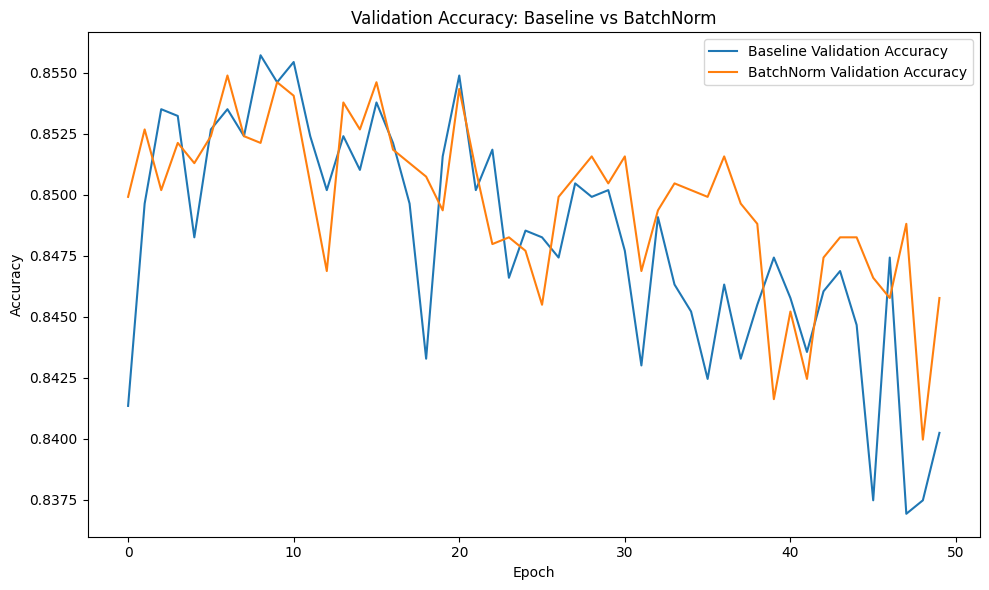

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(
    history_task6_base.history["val_accuracy"],
    label="Baseline Validation Accuracy"
)
plt.plot(
    history_bn.history["val_accuracy"],
    label="BatchNorm Validation Accuracy"
)

plt.title("Validation Accuracy: Baseline vs BatchNorm")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_ann(model, X_test, y_test, model_name):
    probabilities = model.predict(X_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Class 1)": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall (Class 1)": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score (Class 1)": f1_score(
            y_test, predictions, zero_division=0
        )
    }


bn_results = pd.DataFrame([
    evaluate_ann(
        model_task6_base, X_test, y_test, "Baseline"
    ),
    evaluate_ann(
        model_bn, X_test, y_test, "BatchNorm Before Activation"
    )
])

display(bn_results.round(4))


,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-score (Class 1)
0,Baseline,0.836,0.6766,0.6485,0.6623
1,BatchNorm Before Activation,0.843,0.7041,0.6325,0.6664


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8293 - loss: 0.3701 - val_accuracy: 0.8507 - val_loss: 0.3295
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8495 - loss: 0.3227 - val_accuracy: 0.8535 - val_loss: 0.3246
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8538 - loss: 0.3152 - val_accuracy: 0.8530 - val_loss: 0.3268
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8551 - loss: 0.3101 - val_accuracy: 0.8516 - val_loss: 0.3229
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8560 - loss: 0.3087 - val_accuracy: 0.8510 - val_loss: 0.3238
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8577 - loss: 0.3050 - val_accuracy: 0.8513 - val_loss: 0.3265
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8593 - loss: 0.3025 - val_accuracy: 0.8494 - val_loss: 0.3236
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8628 - loss: 0.2984 - val_accuracy: 0.

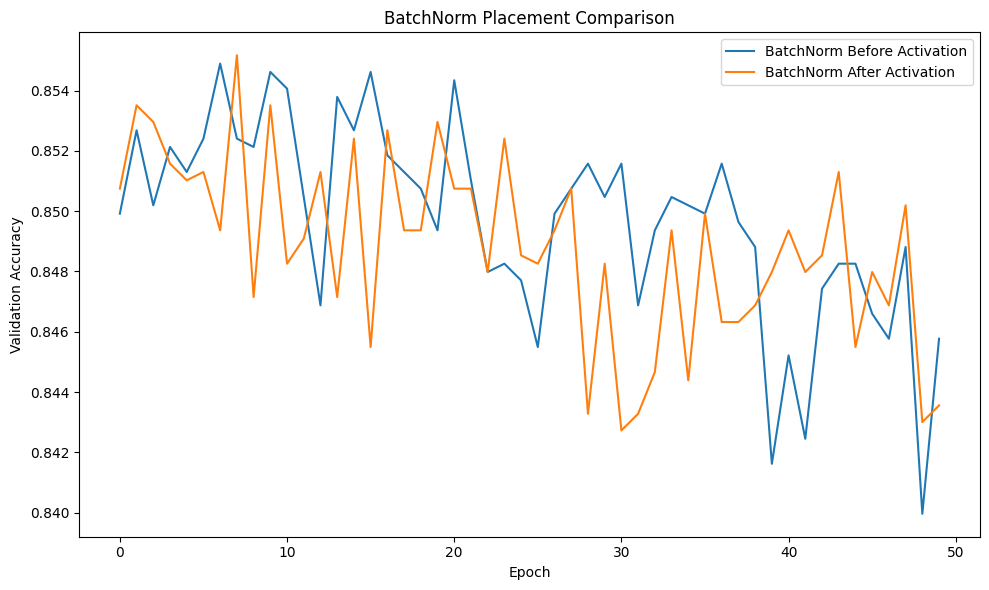

,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-score (Class 1)
0,BatchNorm Before,0.8430,0.7041,0.6325,0.6664
1,BatchNorm After,0.8413,0.6945,0.6427,0.6676


In [ ]:

# Train BatchNorm after activation

model_bn_after = build_ann_bn(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    bn_position="after"
)

history_bn_after = model_bn_after.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

# Compare validation accuracy
plt.figure(figsize=(10, 6))

plt.plot(
    history_bn.history["val_accuracy"],
    label="BatchNorm Before Activation"
)
plt.plot(
    history_bn_after.history["val_accuracy"],
    label="BatchNorm After Activation"
)

plt.title("BatchNorm Placement Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Compare test metrics
placement_results = pd.DataFrame([
    evaluate_ann(
        model_bn, X_test, y_test, "BatchNorm Before"
    ),
    evaluate_ann(
        model_bn_after, X_test, y_test, "BatchNorm After"
    )
])

display(placement_results.round(4))


In [ ]:

# Task 7.1: ANN with configurable regularization

def build_regularized_ann(
    input_dim,
    regularization=None,
    l1_value=0.001,
    l2_value=0.001,
    dropout_rate=0.3
):
    if regularization == "l1":
        reg = keras.regularizers.L1(l1_value)
    elif regularization == "l2":
        reg = keras.regularizers.L2(l2_value)
    elif regularization == "combined":
        reg = keras.regularizers.L2(l2_value)
    else:
        reg = None

    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),

        layers.Dense(
            128,
            activation="relu",
            kernel_initializer="he_normal",
            kernel_regularizer=reg
        ),

        layers.Dropout(
            dropout_rate if regularization in ["dropout", "combined"] else 0.0
        ),

        layers.Dense(
            64,
            activation="relu",
            kernel_initializer="he_normal",
            kernel_regularizer=reg
        ),

        layers.Dropout(
            dropout_rate if regularization in ["dropout", "combined"] else 0.0
        ),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


print("Regularized ANN builder created successfully!")


Regularized ANN builder created successfully!


In [ ]:

# Task 7.2: Compare regularization methods

regularization_types = ["l1", "l2", "dropout", "combined"]

regularized_models = {}
regularized_histories = {}

for reg_type in regularization_types:
    print(f"\nTraining model: {reg_type.upper()}")

    model = build_regularized_ann(
        input_dim=X_train.shape[1],
        regularization=reg_type,
        l1_value=0.001,
        l2_value=0.001,
        dropout_rate=0.3
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    regularized_models[reg_type] = model
    regularized_histories[reg_type] = history

    print(
        "Final training accuracy:",
        round(history.history["accuracy"][-1], 4)
    )
    print(
        "Final validation accuracy:",
        round(history.history["val_accuracy"][-1], 4)
    )

print("\nAll regularization experiments completed!")



Training model: L1
Final training accuracy: 0.8504
Final validation accuracy: 0.8505

Training model: L2
Final training accuracy: 0.8586
Final validation accuracy: 0.8552

Training model: DROPOUT
Final training accuracy: 0.8689
Final validation accuracy: 0.8521

Training model: COMBINED
Final training accuracy: 0.8548
Final validation accuracy: 0.8552

All regularization experiments completed!


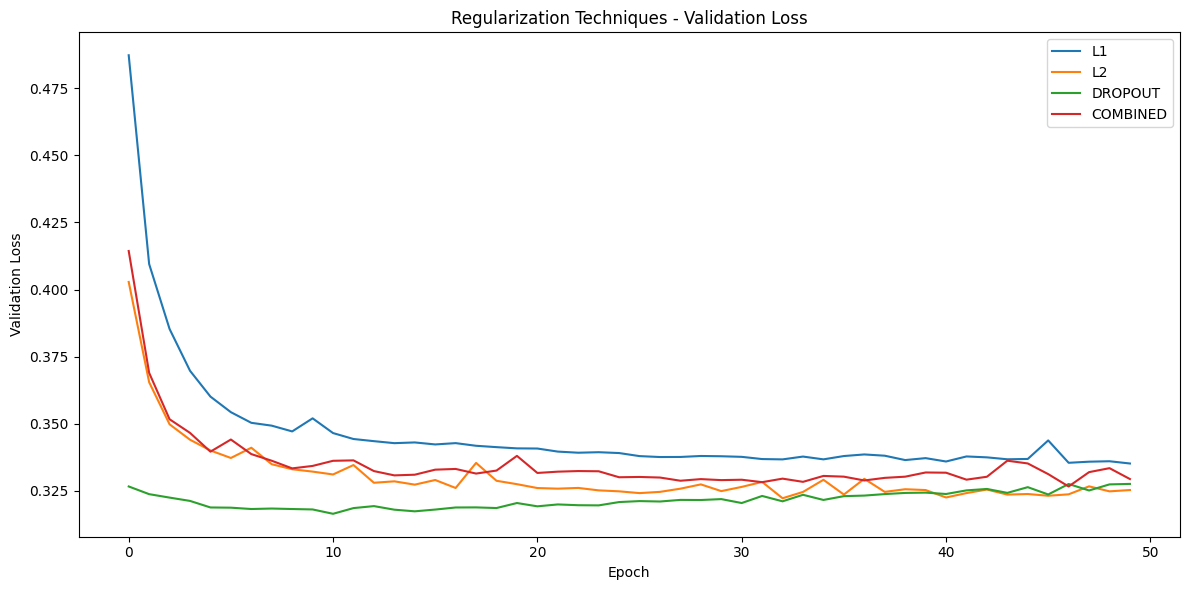

In [ ]:

plt.figure(figsize=(12, 6))

for reg_type in regularization_types:
    history = regularized_histories[reg_type]

    plt.plot(
        history.history["val_loss"],
        label=reg_type.upper()
    )

plt.title("Regularization Techniques - Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()


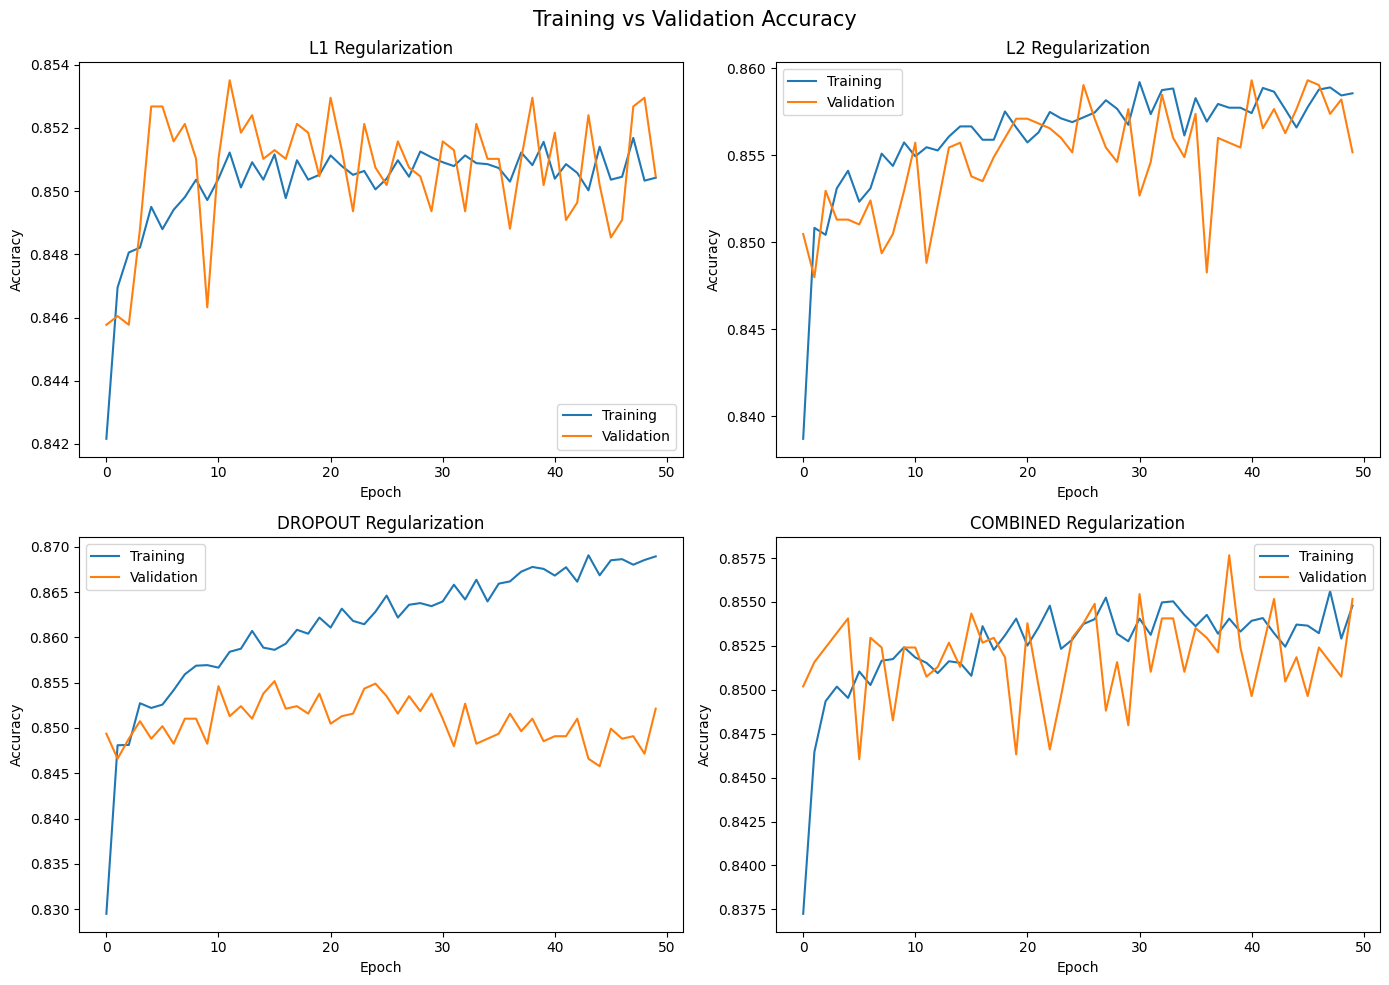

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, reg_type in zip(axes, regularization_types):
    history = regularized_histories[reg_type]

    ax.plot(history.history["accuracy"], label="Training")
    ax.plot(history.history["val_accuracy"], label="Validation")

    ax.set_title(f"{reg_type.upper()} Regularization")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()

plt.suptitle("Training vs Validation Accuracy", fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:

# Task 7.4: Evaluate every regularization model

regularization_results = []

for reg_type in regularization_types:
    model = regularized_models[reg_type]

    result = evaluate_ann(
        model,
        X_test,
        y_test,
        reg_type.upper()
    )

    regularization_results.append(result)

regularization_results_df = pd.DataFrame(
    regularization_results
)

display(
    regularization_results_df.sort_values(
        by="F1-score (Class 1)",
        ascending=False
    ).round(4)
)


,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-score (Class 1)
1,L2,0.8546,0.7493,0.6213,0.6793
3,COMBINED,0.8511,0.7306,0.6325,0.6780
0,L1,0.8505,0.7390,0.6137,0.6706
2,DROPOUT,0.8490,0.7355,0.6102,0.6670


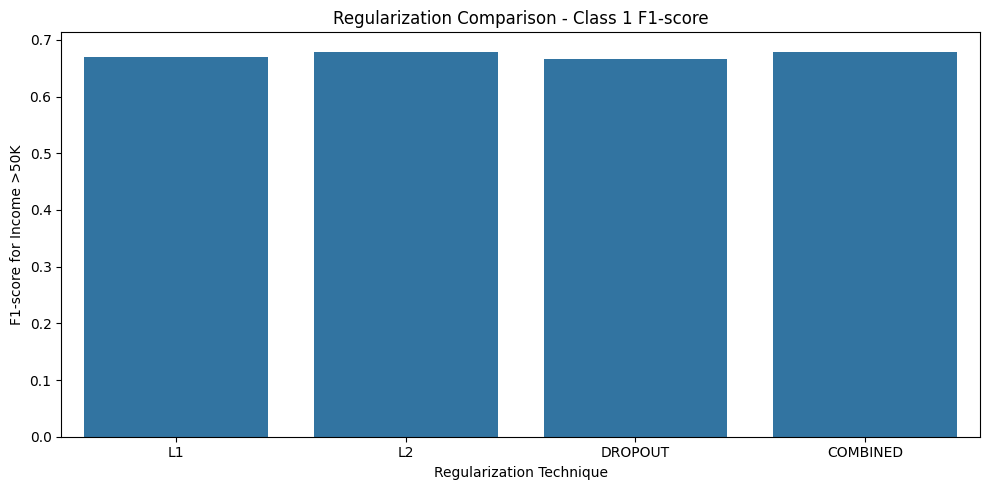

In [ ]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=regularization_results_df,
    x="Model",
    y="F1-score (Class 1)"
)

plt.title("Regularization Comparison - Class 1 F1-score")
plt.xlabel("Regularization Technique")
plt.ylabel("F1-score for Income >50K")
plt.tight_layout()
plt.show()


In [ ]:

l1_model = regularized_models["l1"]

all_weights = []

for layer in l1_model.layers:
    if isinstance(layer, layers.Dense):
        kernel = layer.get_weights()[0]
        all_weights.extend(kernel.flatten())

all_weights = np.array(all_weights)

zero_fraction = np.mean(all_weights == 0)
small_weight_fraction = np.mean(np.abs(all_weights) < 0.01)

print("Total Dense-layer weights:", len(all_weights))
print("Exact zero-weight fraction:", round(float(zero_fraction), 4))
print("Fraction with absolute value < 0.01:",
      round(float(small_weight_fraction), 4))


Total Dense-layer weights: 18496
Exact zero-weight fraction: 0.0
Fraction with absolute value < 0.01: 0.9937


In [ ]:
!pip install -q keras-tuner

import keras_tuner as kt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("KerasTuner version:", kt.__version__)

KerasTuner version: 1.4.8


In [ ]:

def build_tuned_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(X_train.shape[1],)))

    # Tune the number of neurons
    neurons_1 = hp.Choice(
        "neurons_1", values=[64, 128, 256]
    )
    neurons_2 = hp.Choice(
        "neurons_2", values=[32, 64, 128]
    )

    model.add(
        layers.Dense(
            neurons_1,
            activation="relu",
            kernel_initializer="he_normal"
        )
    )

    model.add(
        layers.Dense(
            neurons_2,
            activation="relu",
            kernel_initializer="he_normal"
        )
    )

    model.add(layers.Dense(1, activation="sigmoid"))

    # Tune optimizer and learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.001, 0.0005]
    )

    optimizer_name = hp.Choice(
        "optimizer",
        values=["adam", "rmsprop"]
    )

    if optimizer_name == "adam":
        optimizer = keras.optimizers.Adam(
            learning_rate=learning_rate
        )
    else:
        optimizer = keras.optimizers.RMSprop(
            learning_rate=learning_rate
        )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [ ]:

# Task 8.3: Initialize Random Search

tuner = kt.RandomSearch(
    hypermodel=build_tuned_model,
    objective="val_accuracy",
    max_trials=12,
    executions_per_trial=1,
    directory="adult_income_tuning",
    project_name="ann_hyperparameter_search",
    overwrite=True,
    seed=42
)

tuner.search_space_summary()


Search space summary
Default search space size: 4
neurons_1 (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128, 256], 'ordered': True}
neurons_2 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128], 'ordered': True}
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.0005], 'ordered': True}
optimizer (Choice)
{'default': 'adam', 'conditions': [], 'values': ['adam', 'rmsprop'], 'ordered': False}


In [ ]:

# Tune the model using the training data only

tuner.search(
    X_train,
    y_train,
    validation_split=0.1,
    epochs=30,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("Hyperparameter search completed!")


Trial 12 Complete [00h 00m 15s]
val_accuracy: 0.8573797941207886

Best val_accuracy So Far: 0.8612493276596069
Total elapsed time: 00h 04m 08s
Hyperparameter search completed!


In [ ]:

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameters:")
print("First hidden layer:", best_hp.get("neurons_1"))
print("Second hidden layer:", best_hp.get("neurons_2"))
print("Learning rate:", best_hp.get("learning_rate"))
print("Optimizer:", best_hp.get("optimizer"))

best_model = tuner.get_best_models(num_models=1)[0]

best_model.summary()


Best hyperparameters:
First hidden layer: 64
Second hidden layer: 32
Learning rate: 0.001
Optimizer: rmsprop


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 2 variables whereas the saved optimizer has 8 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,297 (28.50 KB)

 Trainable params: 7,297 (28.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Show the top five configurations

top_trials = tuner.oracle.get_best_trials(num_trials=5)

for rank, trial in enumerate(top_trials, start=1):
    print(f"\nRank {rank}")
    print("Validation score:", trial.score)
    print("Parameters:", trial.hyperparameters.values)



Rank 1
Validation score: 0.8612493276596069
Parameters: {'neurons_1': 64, 'neurons_2': 32, 'learning_rate': 0.001, 'optimizer': 'rmsprop'}

Rank 2
Validation score: 0.8604201078414917
Parameters: {'neurons_1': 128, 'neurons_2': 32, 'learning_rate': 0.0005, 'optimizer': 'rmsprop'}

Rank 3
Validation score: 0.8604201078414917
Parameters: {'neurons_1': 256, 'neurons_2': 32, 'learning_rate': 0.001, 'optimizer': 'rmsprop'}

Rank 4
Validation score: 0.8579325675964355
Parameters: {'neurons_1': 256, 'neurons_2': 64, 'learning_rate': 0.001, 'optimizer': 'rmsprop'}

Rank 5
Validation score: 0.8573797941207886
Parameters: {'neurons_1': 128, 'neurons_2': 128, 'learning_rate': 0.001, 'optimizer': 'adam'}


              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      6803
        >50K       0.75      0.62      0.68      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.78      0.79      9045
weighted avg       0.85      0.85      0.85      9045



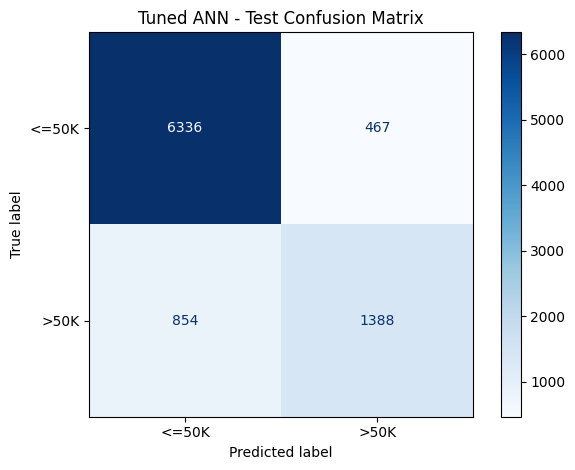

In [ ]:

# Evaluate the selected model on the test set

best_probabilities = best_model.predict(
    X_test,
    verbose=0
).ravel()

best_predictions = (best_probabilities >= 0.5).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print(
    classification_report(
        y_test,
        best_predictions,
        labels=[0, 1],
        target_names=["<=50K", ">50K"],
        zero_division=0
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test, best_predictions, labels=[0, 1]
    ),
    display_labels=["<=50K", ">50K"]
).plot(cmap="Blues", values_format="d")

plt.title("Tuned ANN - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Task 8.6: Compare batch sizes using the selected hyperparameters

batch_size_results = []
batch_size_histories = {}
batch_size_models = {}

for batch_size in [32, 64]:
    print(f"\nTraining with batch size {batch_size}")

    model = build_tuned_model(best_hp)

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=batch_size,
        validation_split=0.1,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=4,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    batch_size_models[batch_size] = model
    batch_size_histories[batch_size] = history

    result = evaluate_ann(
        model,
        X_test,
        y_test,
        f"Batch size {batch_size}"
    )

    batch_size_results.append(result)

display(pd.DataFrame(batch_size_results).round(4))



Training with batch size 32

Training with batch size 64


,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-score (Class 1)
0,Batch size 32,0.8505,0.7266,0.6365,0.6786
1,Batch size 64,0.8531,0.7396,0.6285,0.6795


In [ ]:

# Task 9.1: Collect trained models from previous tasks

final_models = {}

# Task 2 baseline
if "model_base" in globals():
    final_models["Baseline ANN"] = model_base

# Task 3: Activation functions
if "activation_models" in globals():
    for name, model in activation_models.items():
        final_models[f"Activation: {name}"] = model

# Task 4: Weight initializers
if "initializer_models" in globals():
    for name, model in initializer_models.items():
        final_models[f"Initializer: {name}"] = model

# Task 5: Loss functions
for name in ["model_mse", "model_wbce", "model_focal"]:
    if name in globals():
        final_models[name.replace("model_", "").upper()] = globals()[name]

# Task 6: Batch normalization
for name in ["model_bn", "model_bn_after"]:
    if name in globals():
        final_models[name.replace("model_", "").replace("_", " ").title()] = globals()[name]

# Task 7: Regularization
if "regularized_models" in globals():
    for name, model in regularized_models.items():
        final_models[f"Regularization: {name}"] = model

# Task 8: Hyperparameter tuning
if "best_model" in globals():
    final_models["Tuned ANN"] = best_model

print("Models available for final comparison:", len(final_models))
for model_name in final_models:
    print("-", model_name)


Models available for final comparison: 20
- Baseline ANN
- Activation: relu
- Activation: tanh
- Activation: sigmoid
- Activation: elu
- Initializer: glorot_uniform
- Initializer: glorot_normal
- Initializer: he_uniform
- Initializer: he_normal
- Initializer: zeros
- MSE
- WBCE
- FOCAL
- Bn
- Bn After
- Regularization: l1
- Regularization: l2
- Regularization: dropout
- Regularization: combined
- Tuned ANN


In [ ]:

# Task 9.2: Final test-set evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

final_results = []

for model_name, model in final_models.items():
    probabilities = model.predict(X_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    final_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

final_results_df = pd.DataFrame(final_results)

final_results_df = final_results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(final_results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Activation: tanh,0.8471,0.6969,0.6780,0.6873,0.9028
1,Regularization: l2,0.8546,0.7493,0.6213,0.6793,0.9130
2,Activation: elu,0.8473,0.7099,0.6494,0.6783,0.9066
3,Regularization: combined,0.8511,0.7306,0.6325,0.6780,0.9109
4,Tuned ANN,0.8540,0.7482,0.6191,0.6776,0.9095
5,WBCE,0.8112,0.5878,0.7971,0.6766,0.8908
6,Activation: sigmoid,0.8534,0.7522,0.6093,0.6732,0.9126
7,Regularization: l1,0.8505,0.7390,0.6137,0.6706,0.9087
8,Bn After,0.8413,0.6945,0.6427,0.6676,0.8937
9,Regularization: dropout,0.8490,0.7355,0.6102,0.6670,0.9038


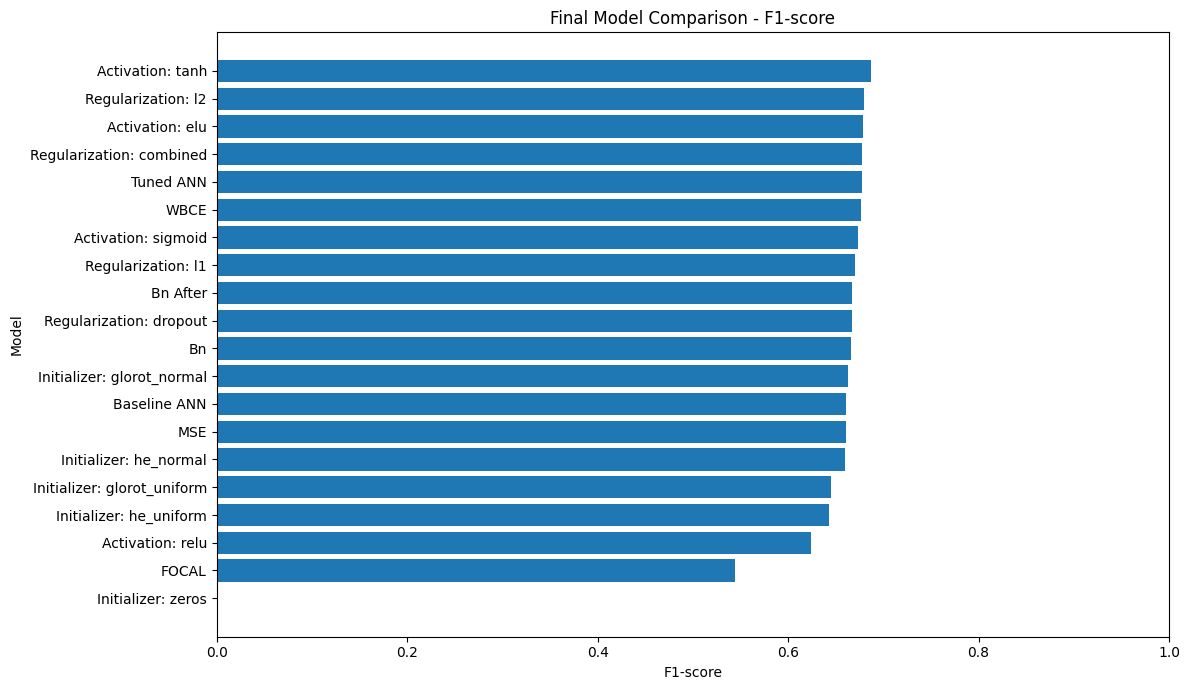

In [ ]:

plt.figure(figsize=(12, max(6, len(final_results_df) * 0.35)))

plot_df = final_results_df.sort_values("F1-score")

plt.barh(plot_df["Model"], plot_df["F1-score"])

plt.title("Final Model Comparison - F1-score")
plt.xlabel("F1-score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


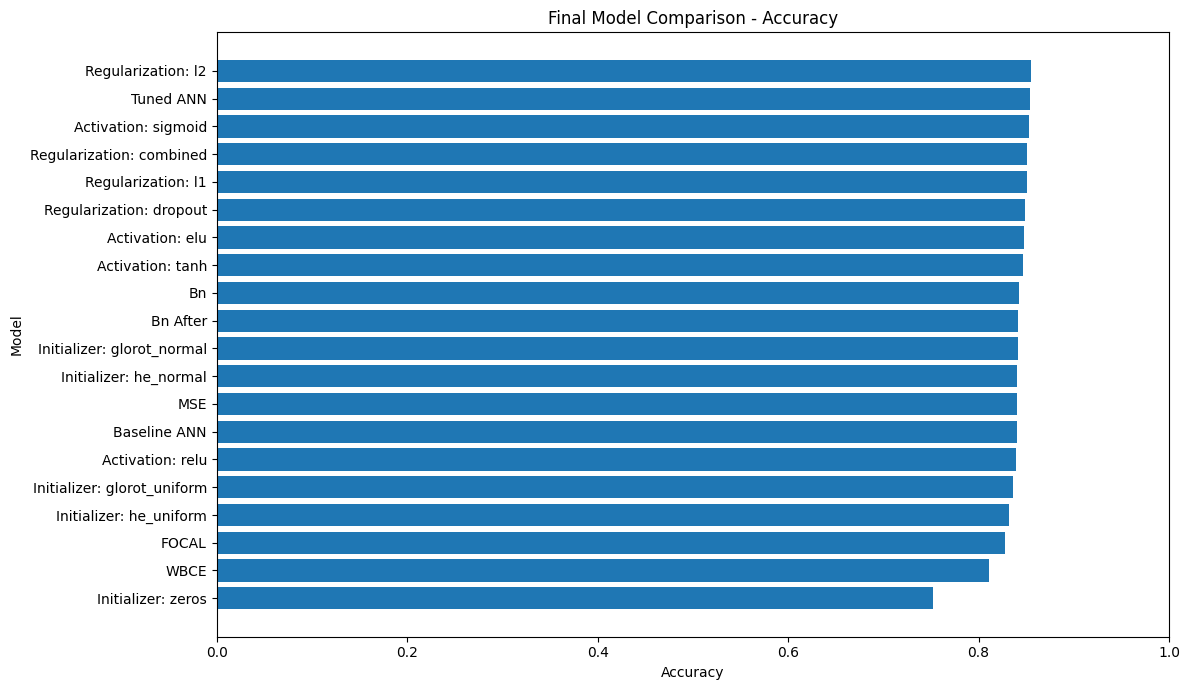

In [ ]:

plot_df = final_results_df.sort_values("Accuracy")

plt.figure(figsize=(12, max(6, len(plot_df) * 0.35)))
plt.barh(plot_df["Model"], plot_df["Accuracy"])

plt.title("Final Model Comparison - Accuracy")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


Top model in this test-set comparison: Activation: tanh


,Value
Model,Activation: tanh
Accuracy,0.847098
Precision,0.696928
Recall,0.677966
F1-score,0.687316
ROC-AUC,0.902782



Final Classification Report:

              precision    recall  f1-score   support

Income <=50K       0.89      0.90      0.90      6803
 Income >50K       0.70      0.68      0.69      2242

    accuracy                           0.85      9045
   macro avg       0.80      0.79      0.79      9045
weighted avg       0.85      0.85      0.85      9045



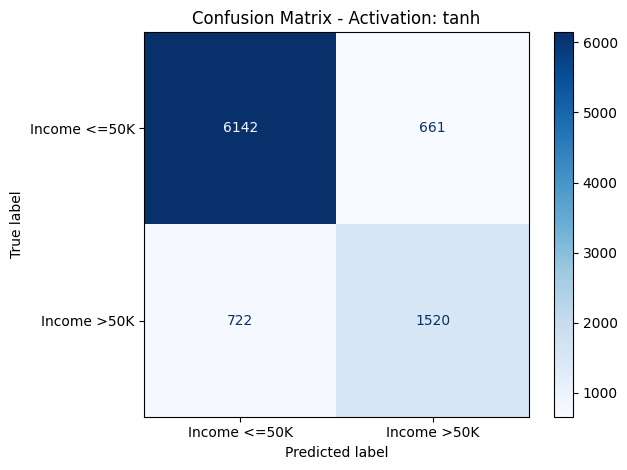

In [ ]:

# Identify the highest test F1-score for descriptive comparison

best_row = final_results_df.iloc[0]
best_model_name = best_row["Model"]
best_final_model = final_models[best_model_name]

print("Top model in this test-set comparison:", best_model_name)
display(best_row.to_frame(name="Value"))

# Final predictions
final_probabilities = best_final_model.predict(
    X_test, verbose=0
).ravel()

final_predictions = (final_probabilities >= 0.5).astype(int)

# Classification report
print("\nFinal Classification Report:\n")
print(
    classification_report(
        y_test,
        final_predictions,
        labels=[0, 1],
        target_names=["Income <=50K", "Income >50K"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Income <=50K", "Income >50K"]
).plot(cmap="Blues", values_format="d")

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()


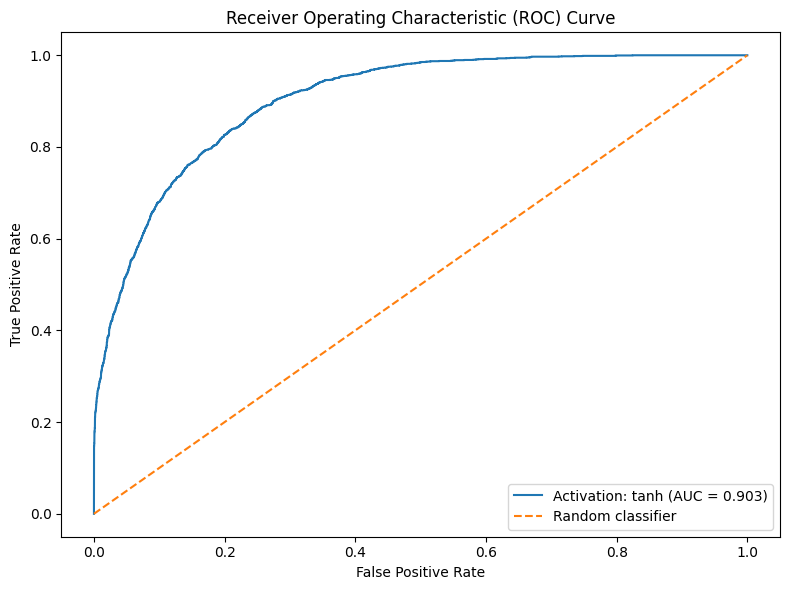

ROC-AUC: 0.9028


In [ ]:

from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_test,
    final_probabilities
)

roc_auc = roc_auc_score(y_test, final_probabilities)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name} (AUC = {roc_auc:.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc, 4))


# Final Conclusion: Adult Income Prediction Using Deep Learning

## 1. Project Objective

The objective of this project was to develop an Artificial Neural Network (ANN) to predict whether an individual's annual income exceeds $50,000 using demographic and employment-related information from the Adult Income Dataset.

## 2. Data Preprocessing

The dataset was cleaned by handling missing values and removing redundant columns. The target variable was encoded as 0 for income less than or equal to $50,000 and 1 for income above $50,000. Categorical features were one-hot encoded, numerical features were standardized, and the dataset was divided into stratified training and testing sets.

## 3. Experiments Conducted

The following experiments were performed:

1. Baseline ANN with hidden layers containing 128 and 64 neurons.
2. Activation function comparison using ReLU, tanh, sigmoid, and ELU.
3. Weight initialization comparison using Glorot Uniform, Glorot Normal, He Uniform, He Normal, and zero initialization.
4. Loss function comparison using Binary Cross-Entropy, Mean Squared Error, Weighted Binary Cross-Entropy, and Focal Loss.
5. Batch Normalization experiments before and after activation.
6. Regularization experiments using L1, L2, Dropout, and combined L2 with Dropout.
7. Hyperparameter tuning involving hidden-layer sizes, learning rate, and optimizer selection.

## 4. Final Model Performance

Based on the experimental results, **the ANN using the tanh activation function achieved the highest F1-score of 0.6873** among the evaluated models.

Its test-set performance was:

- **Accuracy:** 84.71%
- **Precision:** 69.69%
- **Recall:** 67.80%
- **F1-score:** 0.6873
- **ROC-AUC:** 0.9028

These results indicate that the tanh-based ANN achieved a reasonable balance between precision and recall when identifying individuals earning above $50,000.

## 5. Important Experimental Findings

- **Highest F1-score:** Tanh activation model, with an F1-score of 0.6873.
- **Highest accuracy:** L2 regularization model, with an accuracy of 85.46%.
- **Highest precision:** Sigmoid activation model, with a precision of 75.22%.
- **Highest recall:** Weighted Binary Cross-Entropy (WBCE) model, with a recall of 79.71%.
- **Highest ROC-AUC:** L2 regularization model, with a ROC-AUC of 0.9130.
- **Zero initialization:** The model achieved an accuracy of 75.21%, but its precision, recall, and F1-score for the higher-income class were all 0.0000, demonstrating the limitations of zero initialization in a multilayer neural network.

These findings demonstrate that different techniques optimize different performance objectives. The highest-accuracy model is not necessarily the model with the highest F1-score or recall.

## 6. Final Conclusion

This project demonstrated the application of deep learning to a structured tabular classification problem. The experiments showed that activation functions, weight initialization, loss functions, Batch Normalization, regularization, and hyperparameter selection can influence model performance.

The tanh activation model achieved the highest F1-score of 0.6873, while the L2-regularized model achieved the highest accuracy of 85.46% and the highest ROC-AUC of 0.9130. Weighted Binary Cross-Entropy achieved the highest recall of 79.71%, making it a potentially useful option when identifying more higher-income cases is the priority.

Overall, the results demonstrate the importance of evaluating multiple metrics when working with an imbalanced dataset. Accuracy alone does not fully describe classification performance, so precision, recall, F1-score, and ROC-AUC should also be considered.

The project provided practical experience in data preprocessing, ANN architecture design, activation function comparison, weight initialization, loss function selection, normalization, regularization, hyperparameter tuning, and model evaluation.

Further improvements could include threshold optimization, cross-validation, and comparisons with tree-based algorithms such as Random Forest and gradient boosting.

**Note:** These results are based on the displayed test-set comparison. For an unbiased final performance estimate, select the final model using validation data and reserve the test set for the final evaluation.